# Rebound layer

<!-- Oscar writes this -->

## Imports

In [1]:
import sys
from pathlib import Path
here = Path.cwd()
src = next(c for p in [here, *here.parents]
           for c in (p / "src", p / "isa_showcase" / "src", p / "isa_portfolio" / "isa_showcase" / "src",
                     p / "trading_portfolio" / "isa_portfolio" / "isa_showcase" / "src")
           if (c / "showcase_plots.py").exists())
sys.path.insert(0, str(src))
import pandas as pd
import showcase_plots as sp
sp.style()
d = sp.monthly()

After a recession or a sustained poor performing period for equities, markets tend to rebound as investor sentiment changes from being safe, to being willing to invest again. This can lead to certain tickers which are sometimes high-risk or volatile being very suitable for purchase just after such bad period, leading us to consider a rebound basket consisting of equities which have some economic justification of performing better when investors are more willing to purchase again.

## Post re-entry


In [2]:
sp.table("rebound_pooled.csv").T.rename(columns={0: "value"})

,value
episodes,5.000
months,49.000
core_mean_pct_per_month,0.992
rebound_mean_contribution_pp_per_month,1.574
core_plus_defensive_compounded_pct,56.783
plus_rebound_compounded_pct,219.313
share_of_months_rebound_positive,0.633


The chosen basket, chosen based off of the intuition above does infact outperform the core over the period as it was designed too. This basket is held for a fixed period after the exit trigger from a recession is fired.

## From 2001-2026


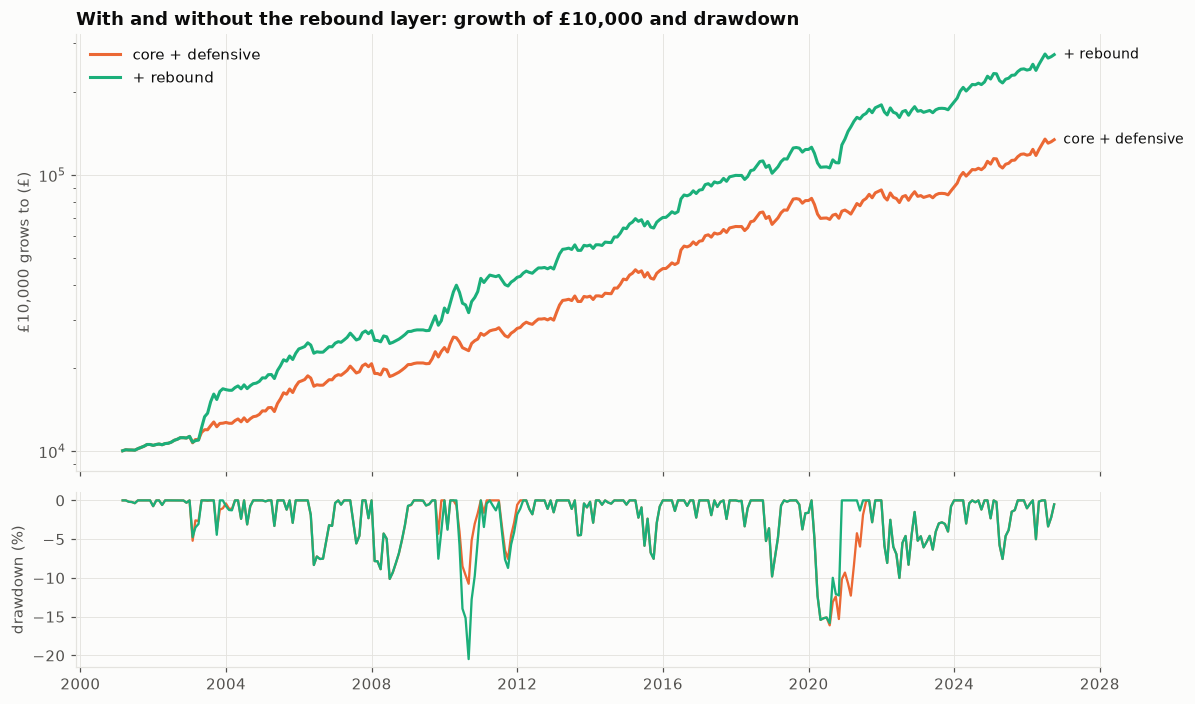

In [3]:
a = d["core"] + d["defensive"]
b = a + d["rebound"]
sp.curves({"core + defensive": a, "+ rebound": b}, {"core + defensive": sp.COLORS["defensive"], "+ rebound": sp.COLORS["rebound"]}, "With and without the rebound layer: growth of £10,000 and drawdown")

It is easy to see the massive relative sucess it has in 2003, 2008 and 2020, 3/4 times the basket was held over this period of history (implicitly counting a false alarm in 2008 the same event as the extended trigger).

## Stats over the entire window


In [4]:
sp.table("parts_stats.csv").query("part == 'rebound'").drop(columns="part").set_index("window")

,months,mean_pp_per_year,vol_pp_per_year,sharpe_of_contribution,best_month_pp,worst_month_pp,sum_pp,correlation_with_core
window,,,,,,,,
full 2001-02–2026-09,308,2.998,5.096,0.588,10.087,-5.028,76.942,0.150
book 2006-01–2026-09,249,2.306,4.952,0.466,10.087,-5.028,47.843,0.138
2001-05,59,5.918,5.632,1.051,7.498,-1.476,29.099,0.220
2006-13,96,2.263,5.765,0.393,7.917,-5.028,18.107,0.276
2014-19,72,0.000,0.000,NaN,0.000,0.000,0.000,NaN
2020-26,81,4.405,5.980,0.737,10.087,-3.114,29.736,0.009


The statistics align with the eye test from the plot in terms of the increase in returns relative to the core. It is quite volatile, as expected by its construction, but does still contribute net Sharpe to the book.